Fortran TRANSPORT namelist editor.

Usage (import this module into your own script):

    from tdata_editor import parse_tdata2, set_tdata2_block, write_updated_namelist

    # 1. Parse all current tdata(2,...) values into a dict
    tdata2_dict = parse_tdata2("transport.nml")

    # 2. Replace one block's values using a 1-D array.
    #    The block is identified by (k, l) — the 3rd and 4th indices of ndata(1,1,k,l) / tdata(...,k,l).
    #    The array length must match ndata(1,k,l) for that block.
    new_weights = [1.5, 1.5, 1.5, 1.5, 1.5, 1.5, 1.5, 1.5, 1.5, ...]   # one value per j
    set_tdata2_block(tdata2_dict, k=1, l=1, values=new_weights)

    # 3. Write the updated file (input is never modified)
    write_updated_namelist("b2.transport.inputfile", "b2.transport.inputfile.new", tdata2_dict)

Dictionary key format:  (2, j, k, l)  ->  float

In [1]:
import re
from pathlib import Path
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from boutdata.data import BoutData

In [2]:
def plot_time_slices(x, y_values, times=None, cmap='viridis', 
                     xlabel='x', ylabel='y', title='Time Evolution',
                     figsize=(10, 6), colorbar_label='Time', time_axis=0):
    # Convert to numpy array if needed
    y_values = np.array(y_values)
    
    # Transpose if time is on axis 1 to get (n_times, n_points)
    if time_axis == 1:
        y_values = y_values.T
    
    # If times not provided, use indices
    if times is None:
        times = np.arange(len(y_values))
    else:
        times = np.array(times)
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Normalize time values for color mapping
    norm = Normalize(vmin=times.min(), vmax=times.max())
    cmap_obj = plt.cm.get_cmap(cmap)
    
    # Plot each time slice
    for i, (y, t) in enumerate(zip(y_values, times)):
        color = cmap_obj(norm(t))
        ax.plot(x, y, color=color, alpha=0.7, linewidth=1.5)
    
    # Add colorbar
    sm = ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, label=colorbar_label)
    
    # Labels and title
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig, ax

## Regex patterns

In [3]:
# Matches any tdata(i, j, k, l) = value — tolerates arbitrary whitespace.
_TDATA_RE = re.compile(
    r"(tdata\(\s*(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\s*\)\s*=\s*)"
    r"([+-]?\d+(?:\.\d*)?(?:[eE][+-]?\d+)?)",
    re.IGNORECASE,
)

# Matches ndata(1, 1, k, l) = N  — used to discover block sizes and identifiers.
_NDATA_RE = re.compile(
    r"ndata\(\s*1\s*,\s*(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\s*\)\s*=\s*(\d+)",
    re.IGNORECASE,
)

# Parse

In [4]:
def parse_tdata2(filepath: str) -> dict:
    """
    Read a TRANSPORT namelist file and return a dictionary of every
    tdata(2, j, k, l) entry found.

    Returns
    -------
    dict : { (2, j, k, l): float, ... }
    """
    tdata2 = {}
    text = Path(filepath).read_text()

    for m in _TDATA_RE.finditer(text):
        i = int(m.group(2))
        if i == 2:
            j, k, l = int(m.group(3)), int(m.group(4)), int(m.group(5))
            tdata2[(2, j, k, l)] = float(m.group(6))

    return tdata2


def parse_block_sizes(filepath: str) -> dict:
    """
    Read a TRANSPORT namelist file and return the declared size of every block.

    Returns
    -------
    dict : { (k, l): N, ... }
        where N = ndata(1, k, l)
    """
    sizes = {}
    text = Path(filepath).read_text()
    for m in _NDATA_RE.finditer(text):
        k, l, n = int(m.group(1)), int(m.group(2)), int(m.group(3))
        sizes[(k, l)] = n
    return sizes

## Block helper

## Write

In [5]:
def write_updated_namelist(input_filepath: str,
                           output_filepath: str,
                           new_values: dict) -> None:
    """
    Write a new namelist file identical to *input_filepath* except that every
    tdata(2, j, k, l) = <old> is replaced with the corresponding value from
    *new_values*.  Everything else (whitespace, tabs, tdata(1,...), ndata, ...)
    is preserved character-for-character.

    Parameters
    ----------
    input_filepath  : path to the original namelist file
    output_filepath : path to write the updated file
    new_values      : dict  { (2, j, k, l): float, ... }
                      Keys absent from the dict are left unchanged.
    """
    text = Path(input_filepath).read_text()

    def replacer(m):
        i = int(m.group(2))
        if i != 2:
            return m.group(0)               # leave tdata(1,...) untouched

        j, k, l = int(m.group(3)), int(m.group(4)), int(m.group(5))
        key = (2, j, k, l)
        if key not in new_values:
            return m.group(0)               # not in dict → unchanged

        formatted = _format_value(new_values[key])
        return m.group(1) + formatted       # group(1) = "tdata(...) = "

    updated_text = _TDATA_RE.sub(replacer, text)
    Path(output_filepath).write_text(updated_text)
    print(f"Updated file written to: {output_filepath}")
    

## Number formatter

In [6]:
def _format_value(value: float) -> str:
    """
    Format a float to match the style typically seen in TRANSPORT namelists.
      1.5, 0.2, 2.5  -> compact decimal   e.g.  '1.5'
      -3.49e-2       -> Fortran sci-not    e.g.  '-3.49E-02'
    """
    if value == 0.0:
        return "0.0"
    abs_val = abs(value)
    # Compact decimal for numbers that look like simple decimals
    if 0.01 <= abs_val < 1e5:
        candidate = f"{value:g}"
        try:
            if float(candidate) == value:
                return candidate
        except ValueError:
            pass
    # Fortran-style scientific notation
    formatted = f"{value:.2E}"
    # Guarantee two-digit exponent (Python on some platforms gives one digit)
    formatted = re.sub(r"E([+-])(\d)$", r"E\g<1>0\2", formatted)
    return formatted

# Inline example — edit and run this file directly to try it out

In [1]:
INPUT_FILE  = "/global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_demonstration/0_iteration/b2.transport.inputfile"   # <-- change this
OUTPUT_FILE = "/global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_demonstration/1_iteration/b2.transport.inputfile"


# ------------------------------------------------------------------
# Step 1: parse
# ------------------------------------------------------------------
tdata2 = parse_tdata2(INPUT_FILE)

NameError: name 'parse_tdata2' is not defined

In [8]:
# Matches ndata(1, j, k, l) = N  — used to discover block sizes and identifiers.
_NDATA_RE = re.compile(
    r"ndata\(\s*1\s*,\s*(\d+)\s*,\s*(\d+)\s*\)\s*=\s*(\d+)",
    re.IGNORECASE,
)

In [9]:
# print("Parsed tdata(2,...) entries:")
# for key in sorted(tdata2):
#     print(f"  tdata{key} = {tdata2[key]}")

block_sizes = parse_block_sizes(INPUT_FILE)
print("\nBlock sizes (ndata(1,k,l)):")
for (k, l), n in sorted(block_sizes.items()):
    print(f"  (k={k}, l={l})  ->  N={n}")


Block sizes (ndata(1,k,l)):
  (k=1, l=1)  ->  N=42
  (k=1, l=3)  ->  N=42
  (k=1, l=4)  ->  N=42
  (k=1, l=5)  ->  N=42
  (k=1, l=6)  ->  N=42
  (k=1, l=7)  ->  N=42
  (k=1, l=8)  ->  N=42
  (k=3, l=1)  ->  N=42
  (k=3, l=3)  ->  N=42
  (k=3, l=4)  ->  N=42
  (k=3, l=5)  ->  N=42
  (k=3, l=6)  ->  N=42
  (k=3, l=7)  ->  N=42
  (k=3, l=8)  ->  N=42
  (k=4, l=1)  ->  N=42


In [10]:
import numpy as np
from pathlib import Path
bout_dir  = Path("/global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_demonstration/1_iteration/Shelf_new_grid2_sinks2_gradfix")
data_dir  = bout_dir / "numpy"

In [11]:
bout_dir

PosixPath('/global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_demonstration/1_iteration/Shelf_new_grid2_sinks2_gradfix')

In [14]:
jomp = 44
solps_dir = Path("/global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_demonstration/1_iteration")
bout_dir  = Path("/global/cfs/projectdirs/m4491/irvinam/bout-runs/6f-modified/Shelf_new_grid2_sinks2_gradfix")
data_dir  = bout_dir / "numpy"
grid_fname= bout_dir / "d3d_shelf_184016.03200_nc3.grd.nc"
grid_fname = str(grid_fname)
d = BoutData(path=bout_dir)

/global/homes/b/btaczak/.conda/envs/bout-data/lib/python3.13/site-packages/boutdata/data.py:765: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: [Errno 2] No such file or directory: '"d3d_shelf_184016.03200_nc3.grd.nc"'
Evaluating non-scalar options not available
  alwayswarn(


In [15]:
grid = DataFile(grid_fname)
try:
    _ = grid["psi_bdry"]
    has_psi_bdry = True
except Exception:
    has_psi_bdry = False
    
if has_psi_bdry:
    psi_bndry = grid["psi_bdry"]
else:
    psi_bndry = grid["psi_bndry"]

    
jomp = 44#np.argmax(grid["psixy"][0,:])
psi_midplane = grid["psixy"][:,jomp]
psin_midplane = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:,jomp]

In [16]:
vars_to_plot_list = ["Da_t"]
vars_to_plot_averaged = {}
N = 100
l = 130
for var_name in vars_to_plot_list:
    var = np.load(data_dir / f"{var_name}.npy")
    print(var_name)
    print(var.shape)
    if len(var.shape) == 4:
        var = np.sum(var, axis=3) / var.shape[3]
    var = np.transpose(var, (1, 2, 0))
    (ix,jy,t_all) = var.shape
    var_tilde = np.zeros((ix,jy,l))
    for t in range(l):
        if t == 0:
            var_tilde[:,:,0] = var[:,:,0]
        elif l < N:
            if t == 0:
                var_tilde[:,:,t] = var[:,:,0]
            else:
                if var_name == "Da_t":
                    var_tilde[:,:,t] = np.maximum(0,(1/N) * np.sum(var[:,:,:t],axis=2)+((N-l)/N)*var[:,:,(t-1)])
                else:
                    var_tilde[:,:,t] = (1/N) * np.sum(var[:,:,:t],axis=2)+((N-l)/N)*var[:,:,(t-1)]
        elif l >= N:
            if var_name == "Da_t":
                var_tilde[:,:,t] = np.maximum(0,(1/l) * np.sum(var[:,:,:t],axis=2))
            else:
                var_tilde[:,:,t] = (1/l) * np.sum(var[:,:,:t],axis=2)
            
    vars_to_plot_averaged[var_name] = var_tilde

Da_t
(196, 260, 64)


In [17]:
import re

def extract_tdata_first_index(filepath):
    with open(filepath, 'r') as f:
        text = f.read()
    
    # Match tdata(1, j, *, *) entries only
    pattern = r'tdata\s*\(\s*1\s*,\s*(\d+)\s*,\s*\d+\s*,\s*\d+\s*\)\s*=\s*([+-]?\d*\.?\d+[eE]?[+-]?\d*)'
    
    matches = re.findall(pattern, text, re.IGNORECASE)
    
    if not matches:
        print("No tdata(1,...) entries found.")
        return []
    
    # Sort by j-index, deduplicate, extract values
    seen = {}
    for j_idx, val in matches:
        j = int(j_idx)
        if j not in seen:
            seen[j] = float(val)
    
    values = [seen[j] for j in sorted(seen.keys())]
    return np.array(values)

# def normalize_psin_values(values):
#     return values/np.min(values) * np.

# --- Usage ---
path = "/global/cfs/projectdirs/m4491/btaczak/solps-runs/HvsD_D_lower_noC/Matched_Prof_D_noC_new/b2.transport.inputfile"   # <-- change this
values = extract_tdata_first_index(path)
print(f"Extracted {len(values)} values:")
print(values)

import numpy as np
import netCDF4 as nc
from scipy.interpolate import interp1d

def get_all_midplane_distances(gridfile_path):
    """
    Compute the distance from the separatrix at the outboard midplane
    for every radial flux surface in a BOUT++ grid file.

    Parameters
    ----------
    gridfile_path : str
        Path to the BOUT++ NetCDF grid file.

    Returns
    -------
    psin_mid : np.ndarray, shape (nx,)
        Normalised psi at the midplane for each radial index.
    dist_mid : np.ndarray, shape (nx,)
        Signed distance from the separatrix at the midplane [metres].
        Negative = inside separatrix (core), Positive = outside (SOL).
    """
    with nc.Dataset(gridfile_path, 'r') as ds:
        def load(var):
            return np.array(ds.variables[var][:])

        Rxy       = load('Rxy')       # shape (nx, ny)
        Zxy       = load('Zxy')       # shape (nx, ny)
        psixy     = load('psixy')     # shape (nx, ny)
        psi_axis  = float(ds.variables['psi_axis'][:])
        psi_bndry = float(ds.variables['psi_bdry'][:])

    # --- Normalise psi ---
    psinxy = (psixy - psi_axis) / (psi_bndry - psi_axis)  # (nx, ny)

    nx, ny = Rxy.shape

    # --- Find outboard midplane y-index ---
    outboard_x = np.argmax(Rxy[:, ny // 2])
    Z_along_y  = Zxy[outboard_x, :]
    mid_y      = int(np.argmin(np.abs(Z_along_y)))

    # --- Extract radial profiles at the midplane ---
    R_mid    = Rxy[:, mid_y]       # shape (nx,)
    psin_mid = psinxy[:, mid_y]    # shape (nx,)

    # --- Separatrix R at midplane by interpolation ---
    sort_idx     = np.argsort(psin_mid)
    psin_sorted  = psin_mid[sort_idx]
    R_sorted     = R_mid[sort_idx]

    _, unique_idx = np.unique(psin_sorted, return_index=True)
    psin_sorted   = psin_sorted[unique_idx]
    R_sorted      = R_sorted[unique_idx]

    R_sep_interp = interp1d(psin_sorted, R_sorted, kind='cubic',
                            bounds_error=False, fill_value='extrapolate')
    R_sep = float(R_sep_interp(1.0))

    # --- Signed distance for every flux surface ---
    dist_mid = R_mid - R_sep   # shape (nx,)

    return psin_mid, dist_mid


Extracted 42 values:
[-0.0349   -0.0325   -0.0279   -0.0238   -0.0201   -0.0167   -0.0138
 -0.0111   -0.00884  -0.00685  -0.00514  -0.00369  -0.00249  -0.00152
 -0.000753 -0.000184  0.000184  0.000484  0.000855  0.0013    0.00182
  0.00243   0.00311   0.00388   0.00474   0.00569   0.00674   0.00789
  0.00914   0.0105    0.012     0.0136    0.0153    0.0171    0.019
  0.0211    0.0233    0.0256    0.0281    0.0307    0.0335    0.0349  ]


In [18]:
# --- Usage ---
gridfile = "/global/cfs/projectdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC/Shelf_new_grid2_sinks2_gradfix/d3d_shelf_184016.03200_nc3.grd.nc"

# Single value
psin_mid, distances = get_all_midplane_distances(gridfile)

In [19]:
import numpy as np
from scipy.interpolate import interp1d

def interpolate_dataset(x_data, y_data, x_query, extrapolate=False):
    x_data  = np.asarray(x_data,  dtype=float)
    y_data  = np.asarray(y_data,  dtype=float)
    x_query = np.atleast_1d(np.asarray(x_query, dtype=float))

    if x_data.shape != y_data.shape:
        raise ValueError(f"x_data and y_data must have the same length "
                         f"({len(x_data)} vs {len(y_data)}).")

    if len(x_data) < 2:
        raise ValueError("At least 2 data points are required for interpolation.")

    # Sort by x in case data is unordered
    sort_idx = np.argsort(x_data)
    x_data   = x_data[sort_idx]
    y_data   = y_data[sort_idx]

    fill = 'extrapolate' if extrapolate else np.nan
    interpolator = interp1d(x_data, y_data, kind='linear',
                            bounds_error=False, fill_value=fill)

    y_query = interpolator(x_query)

    # Warn about any out-of-range queries when not extrapolating
    if not extrapolate:
        out_of_range = (x_query < x_data[0]) | (x_query > x_data[-1])
        if np.any(out_of_range):
            print(f"Warning: {out_of_range.sum()} query point(s) are outside "
                  f"the data range [{x_data[0]}, {x_data[-1]}] and will be NaN.")

    return float(y_query[0]) if y_query.size == 1 else y_query

In [21]:
outputs = interpolate_dataset(distances,vars_to_plot_averaged['Da_t'][:,jomp,-1],values)
nan_mask = np.isnan(outputs)
outputs[nan_mask]=0

Text(0, 0.5, 'Normalized flux contribution')

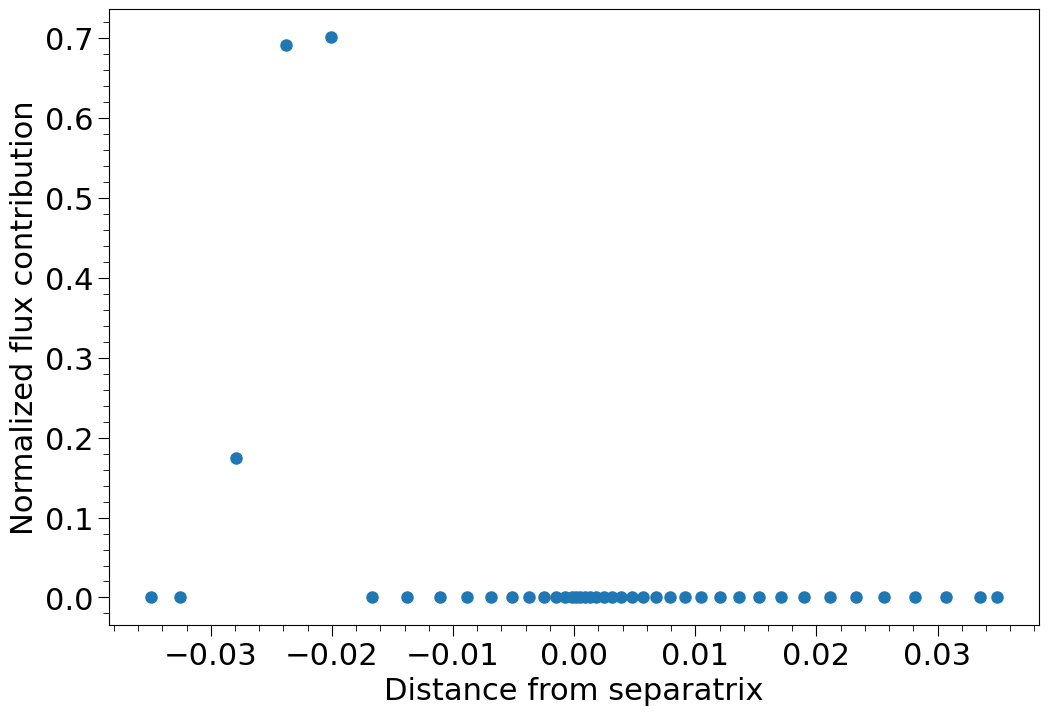

In [23]:
plt.scatter(values,outputs/np.linalg.norm(outputs))
plt.xlabel("Distance from separatrix")
plt.ylabel("Normalized flux contribution")

In [24]:
def set_tdata2_block(tdata2_dict: dict, k: int, l: int, turbulent_profile, percentage: float=1.0) -> None:
    """
    Replace all tdata(2, j, k, l) entries for a given (k, l) block using a
    1-D array of new values.

    Parameters
    ----------
    tdata2_dict : dict (modified in-place)
        The dictionary returned by parse_tdata2() (or a copy of it).
    k, l        : int
        The 2rd and 3rd indices identifying the block, e.g. k=1, l=1
        corresponds to the block guarded by  ndata(1,1,1)=N.
    values      : sequence of float
        1-D array/list of length N.  values[0] -> j=1, values[1] -> j=2, …
        Length must equal the number of j entries in that block.
    percentage  : float
        The percentage of the total cross field transport provided by the
        turbulence

    Raises
    ------
    ValueError  if len(values) doesn't match the number of existing j entries
                for (k, l) in tdata2_dict.
    """
    num_js = block_sizes[(1, 1)]
    js = np.arange(1,block_sizes[(1, 1)])

    # Create the array
    orig_profile = np.zeros(num_js)
    for j in js:
        orig_profile[j] = tdata2_dict[2,j+1,k,l]
    
    # Normalize the turbulent components of the flux
    total_flux_magnitude = np.linalg.norm(orig_profile)
    print("Original profile: ", orig_profile)
    turbulent_flux_magnitude = np.linalg.norm(turbulent_profile)
    turbulence_contributions = percentage * (turbulent_profile/turbulent_flux_magnitude) * total_flux_magnitude
    print("New profile: ", orig_profile + turbulence_contributions)
        
    for j, turbulence_contribution in zip(js, turbulence_contributions):
        tdata2_dict[(2, j, k, l)] = tdata2_dict[(2, j, k, l)] + turbulence_contribution

**Particle density-driven diffusivity**
kind coeff.eq.1 ⇒ dna0  
**Ion thermal anomalous diffusivity**
kind coeff.eq.3 ⇒ hcib  
**Electron thermal anomalous diffusivity**
kind coeff.eq.4 ⇒ hce0

In [25]:
# ------------------------------------------------------------------
# Step 2: supply new values for each block as a 1-D array
#
# Replace the lists below with your actual arrays.
# Each list must have exactly N entries where N = ndata(1,1,k,l).
# ------------------------------------------------------------------
tdata2 = parse_tdata2(INPUT_FILE)

try:
    outputs.shape[0] == block_sizes[(1, 1)]
except ValueError:
    pass
    
percentage = 0.005 # percentage of the cross field transport that has a turbulent contribution

# set particle density-driven diffusivity
set_tdata2_block(tdata2,k=1,l=1,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=1,l=3,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=1,l=4,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=1,l=5,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=1,l=6,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=1,l=7,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=1,l=8,turbulent_profile=outputs,percentage=0.5)

# set ion thermal anomalous diffusivity
set_tdata2_block(tdata2,k=3,l=1,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=3,l=3,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=3,l=4,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=3,l=5,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=3,l=6,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=3,l=7,turbulent_profile=outputs,percentage=0.5)
set_tdata2_block(tdata2,k=3,l=8,turbulent_profile=outputs,percentage=0.5)

# set electron thermal anomalous diffusivity
set_tdata2_block(tdata2,k=4,l=1,turbulent_profile=outputs,percentage=0.5)

# # Example: block (k=1, l=1) — all weights set to 1.5
# n_block_1_1 = block_sizes[(1, 1)]
# new_weights_1_1 = outputs          # <-- replace with your array

# set_tdata2_block(tdata2, k=1, l=1, values=new_weights_1_1)

# # Example: block (k=1, l=3)
# n_block_1_3 = block_sizes[(1, 3)]
# new_weights_1_3 = [2.0] * n_block_1_3          # <-- replace with your array

# set_tdata2_block(tdata2, k=1, l=3, values=new_weights_1_3)

# ------------------------------------------------------------------
# Step 3: write
# ------------------------------------------------------------------
write_updated_namelist(INPUT_FILE, OUTPUT_FILE, tdata2)

Original profile:  [0.  1.5 1.5 1.5 1.5 1.5 1.5 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 2.5 2.5 2.5 2.5 2.5 2.5
 2.5 2.5 2.5 2.5 2.5 2.5]
New profile:  [0.         1.5        2.32542106 4.77013956 4.81358829 1.5
 1.5        0.2        0.2        0.2        0.2        0.2
 0.2        0.2        0.2        0.2        0.2        0.2
 0.2        0.2        0.2        0.2        0.2        0.2
 0.2        0.2        0.2        0.2        0.2        0.2
 2.5        2.5        2.5        2.5        2.5        2.5
 2.5        2.5        2.5        2.5        2.5        2.5       ]
Original profile:  [0.  1.5 1.5 1.5 1.5 1.5 1.5 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 2.5 2.5 2.5 2.5 2.5 2.5
 2.5 2.5 2.5 2.5 2.5 2.5]
New profile:  [0.         1.5        2.32542106 4.77013956 4.81358829 1.5
 1.5        0.2        0.2        0.2        0.2        0.2
 0.2        0.2        0.2        0.2     